# AIMMD-TIS on the Wolfe–Quapp potential: a walkthrough

This notebook goes through a finished iterative AIMMD-TIS run. It shows, iteration by iteration, how the learned committor improves, and which diagnostics show that.

**The loop** (`run_iterative.py`):
1. **Seed.** Short AIMMD-TPS gives a first logit committor $q_0(x)$. Stable-state MD in A and B gives the flux and the $q$ range of each state.
2. **Interfaces.** TIS interfaces are placed on contours of $q_k$, between $\max_{A} q_k$ and $\min_{B} q_k$.
3. **TIS.** TIS runs forward (from A) and backward (from B), in parallel. Path descriptors, shot results and path extrema are stored while sampling.
4. **Reweighting.** MultiSet-MBAR combines all interface sets $q_0 \dots q_k$ into one reweighted path ensemble, RPE$_k$: every frame gets an equilibrium weight. Stable-state MD is added by flux matching at the joined first interface.
5. **Retraining.** A new model $q_{k+1}$ is trained on RPE$_k$ with the weighted log-likelihood plus a smoothness term, then the loop repeats.

**What to look at.** The diagnostics follow *Training, validation, and interpretation of committor models based on reweighted path ensembles* (Breebaart & Bolhuis, JCP 165, 124125, 2026). Each section starts with a "what to look for" note. Because this is a toy potential, the exact committor and free energy (`theory/`) are also available, so every diagnostic can be checked against the truth.

Run the loop (resumable; TIS ensembles run in parallel) with:
```bash
python run_iterative.py --out results_it_100_steps --stage all --tis-steps 100 --until-converged
```

In [12]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

import warnings
import run_iterative as ri
import diagnostics as dg

warnings.filterwarnings("ignore", category=RuntimeWarning)   # empty-bin log/divide warnings in plots

OUT = Path("results_harmonics20")  # finished (or running) run folder

cfg = ri.load_run_config(OUT)        # the config the run was started with
with dg.quiet():                      # hide the toy-system setup messages
    wf = ri.IterativeAimmdTIS(cfg, OUT, n_workers=1)
metrics = dg.iteration_metrics(OUT)
LAST = int(metrics["iteration"].max())
SHOW = sorted({0, 1, min(3, LAST), LAST})   # iterations shown in the per-iteration sections
theory_path = wf.theory_path()
print(f"{len(metrics)} iterations; showing {SHOW}; exact committor: {theory_path.name}")

12 iterations; showing [0, 1, 3, 11]; exact committor: wolfe_quapp_scale2_rot0_d1_T1_n201_committor.npy


## 1. The run at a glance
One row per iteration:
- `n_ifaces` and `n_paths`: the interface ensembles sampled, and the paths (all interface sets so far) that enter the MultiSet-MBAR.
- `P_forward` and `P_backward`: the reweighted fraction of reactive paths, i.e. $P(\lambda_B|\lambda_0)$ through the joined first interface.
- `k_AB` and `k_BA`: the rates, flux × $P$.
- `delta_q_rms`: how much retraining still changes the model. This is the theory-free stopping rule.

In [13]:
cols = ["iteration", "n_ifaces", "n_paths", "P_forward", "P_backward", "k_AB", "k_BA", "delta_q_rms"]
metrics[[c for c in cols if c in metrics]].style.format(precision=3).format(
    {c: "{:.2e}" for c in ("P_forward", "P_backward", "k_AB", "k_BA")})

,iteration,n_ifaces,n_paths,P_forward,P_backward,k_AB,k_BA,delta_q_rms
0,0,9,1786,1.64e-05,9.37e-04,4.50e-06,2.26e-04,7.939397
1,1,16,4949,1.69e-05,3.04e-04,5.31e-06,8.31e-05,2.098123
2,2,14,7564,2.03e-05,2.50e-04,6.65e-06,7.91e-05,0.556675
3,3,13,9932,9.89e-06,1.35e-04,4.62e-06,4.26e-05,1.451619
4,4,15,12903,9.66e-06,2.51e-04,4.81e-06,1.27e-04,0.313854
5,5,14,15670,1.01e-05,1.66e-04,5.21e-06,8.48e-05,0.185470
6,6,16,18839,1.27e-05,1.22e-04,6.57e-06,6.21e-05,0.117809
7,7,16,22016,1.37e-05,1.14e-04,7.16e-06,5.87e-05,0.124155
8,8,16,25192,1.70e-05,9.44e-05,8.91e-06,4.94e-05,0.114391
9,9,15,28160,1.70e-05,8.11e-05,8.91e-06,4.24e-05,0.082123


## 2. Where TIS samples: interfaces on $q_k$
**Left:** the iteration's interfaces as contours of $q_k$ on the potential; red from A, blue from B. **Right:** $q_k$ of the stable-state MD frames. Interfaces lie between the two state histograms, so none cuts into a state.

**What to look for:** with a poor $q_0$ the interfaces are nearly straight lines that ignore the channels of the potential. As $q_k$ improves they bend around the states and follow the isocommittor surfaces, and the $q$ range they cover widens (the model resolves smaller committor values).

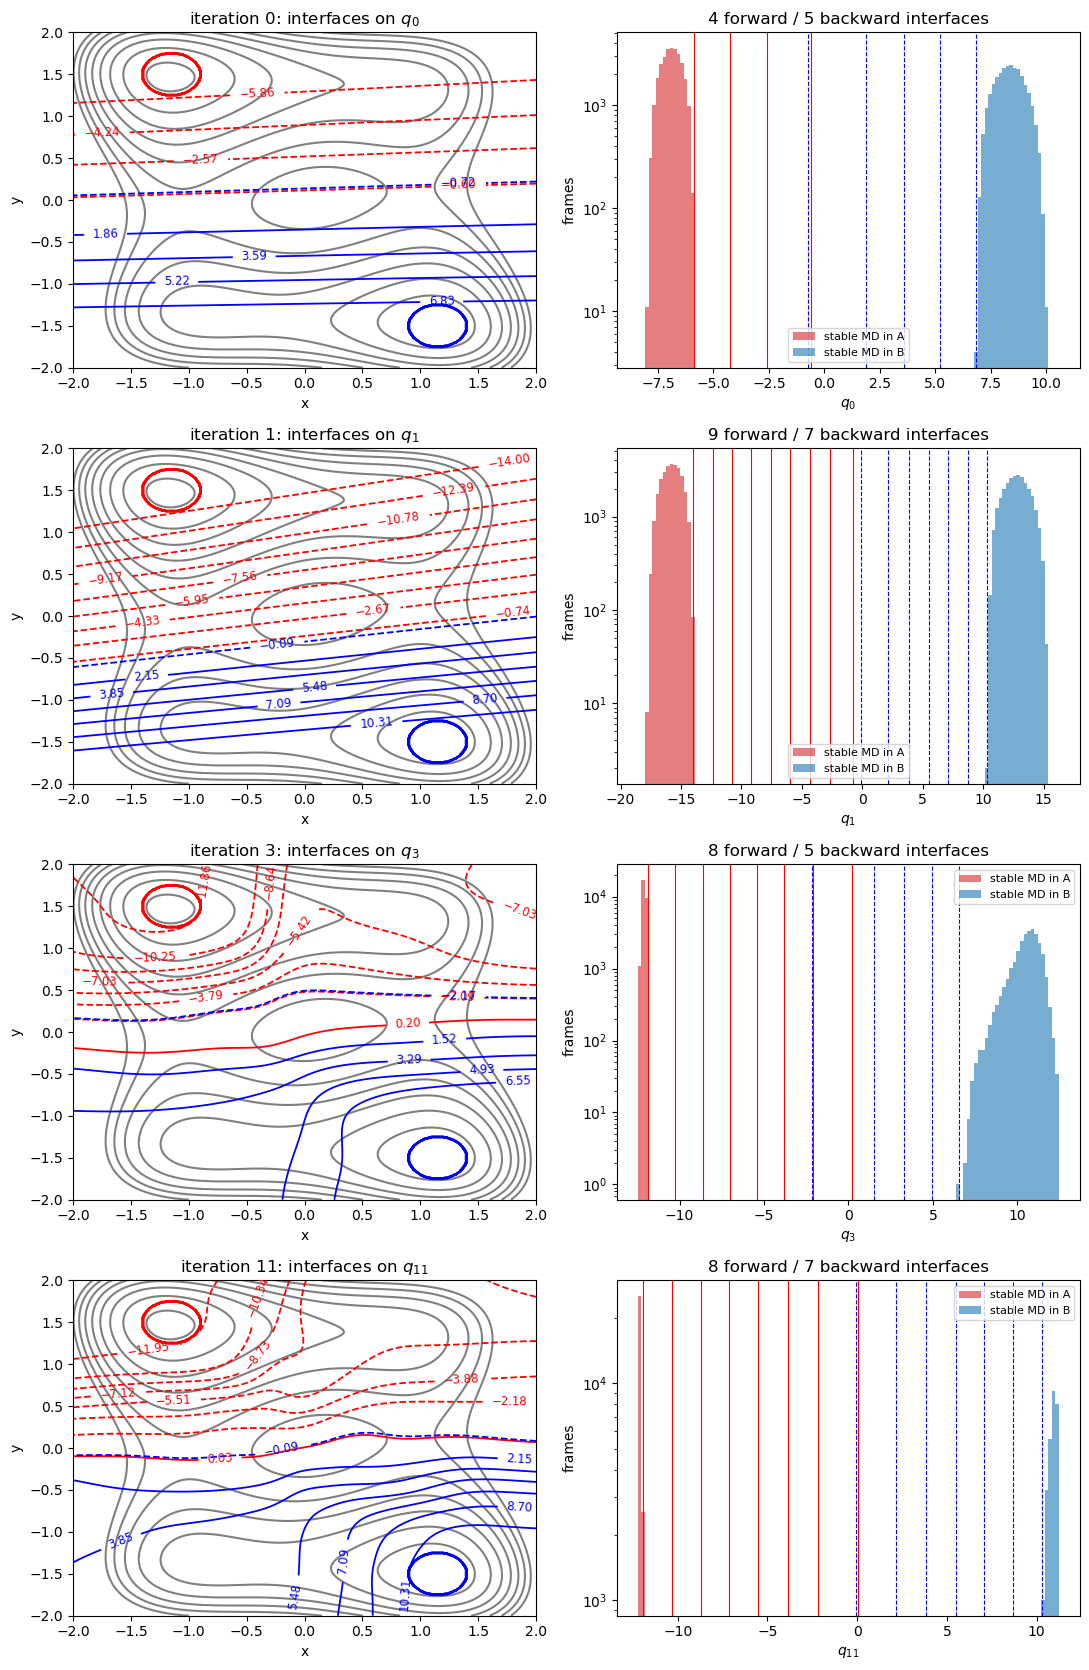

In [14]:
fig, axes = plt.subplots(len(SHOW), 2, figsize=(11, 4.2 * len(SHOW)))
for row, k in zip(axes, SHOW):
    dg.plot_interfaces(wf, k, axes=row)
fig.tight_layout()

## 2b. Are both reaction channels sampled?
Wolfe–Quapp has two channels from A (upper left) to B (lower right): a **left** one running down along $x \approx -1$ and a **right** one along $x \approx +1$. A reactive path's channel is read from where it first crosses $y = 0$. The histograms show the reweighted distribution of that position; the title gives the exact share of the reactive flux through the right channel, computed from the exact committor.

**What to look for:** both channels sampled, with the right-channel fraction near the exact value. TIS samples a channel only if its chains reach it. If every chain starts from the same path, a 100-step chain rarely crosses the barrier between the channels. Continuing chains across iterations (`run.reseed`) and longer chains (`--tis-steps`) both help.

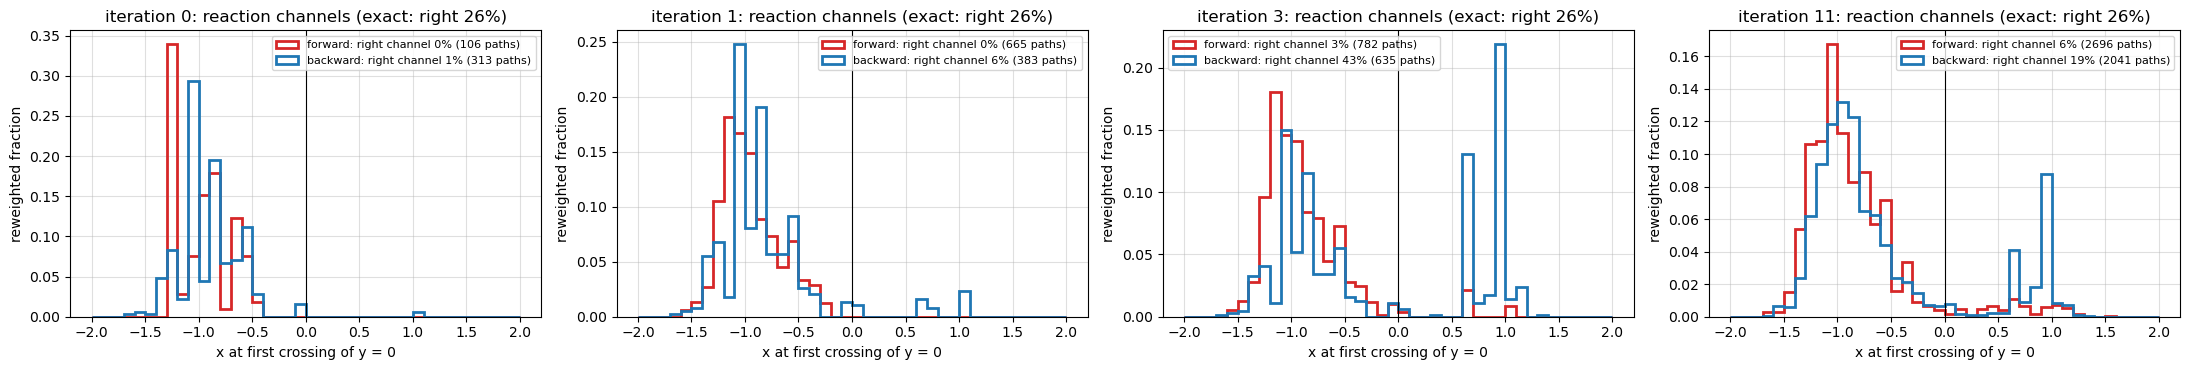

In [15]:
fig, axes = plt.subplots(1, len(SHOW), figsize=(5.5 * len(SHOW), 3.8))
for ax, k in zip(np.atleast_1d(axes), SHOW):
    dg.plot_channels(wf, k, ax=ax)
fig.tight_layout()

## 3. Global validation: crossing probabilities against the ideal committor
For an exact committor the TIS crossing probability is fixed by $q$ itself: $P(q|q_i) = (1+e^{-q})/(1+e^{-q_i})$ (JCP Eq. 12). Here it is measured from the RPE paths of iteration $k$ in the model trained on them, $q_{k+1}$ (solid), for five reference interfaces $q_i$, against that ideal relation (dashed). The curves flatten where paths reach the other state.

**What to look for:**
- **Convergence:** the solid curves approach the dashed ones.
- **Miscalibration:** curves that drop much faster or slower than the ideal mean the model is too steep or too shallow.
- **"Bubbles"** (non-monotonic regions in $q$): dips or jumps.

This is the paper's global check; it needs no extra simulation.

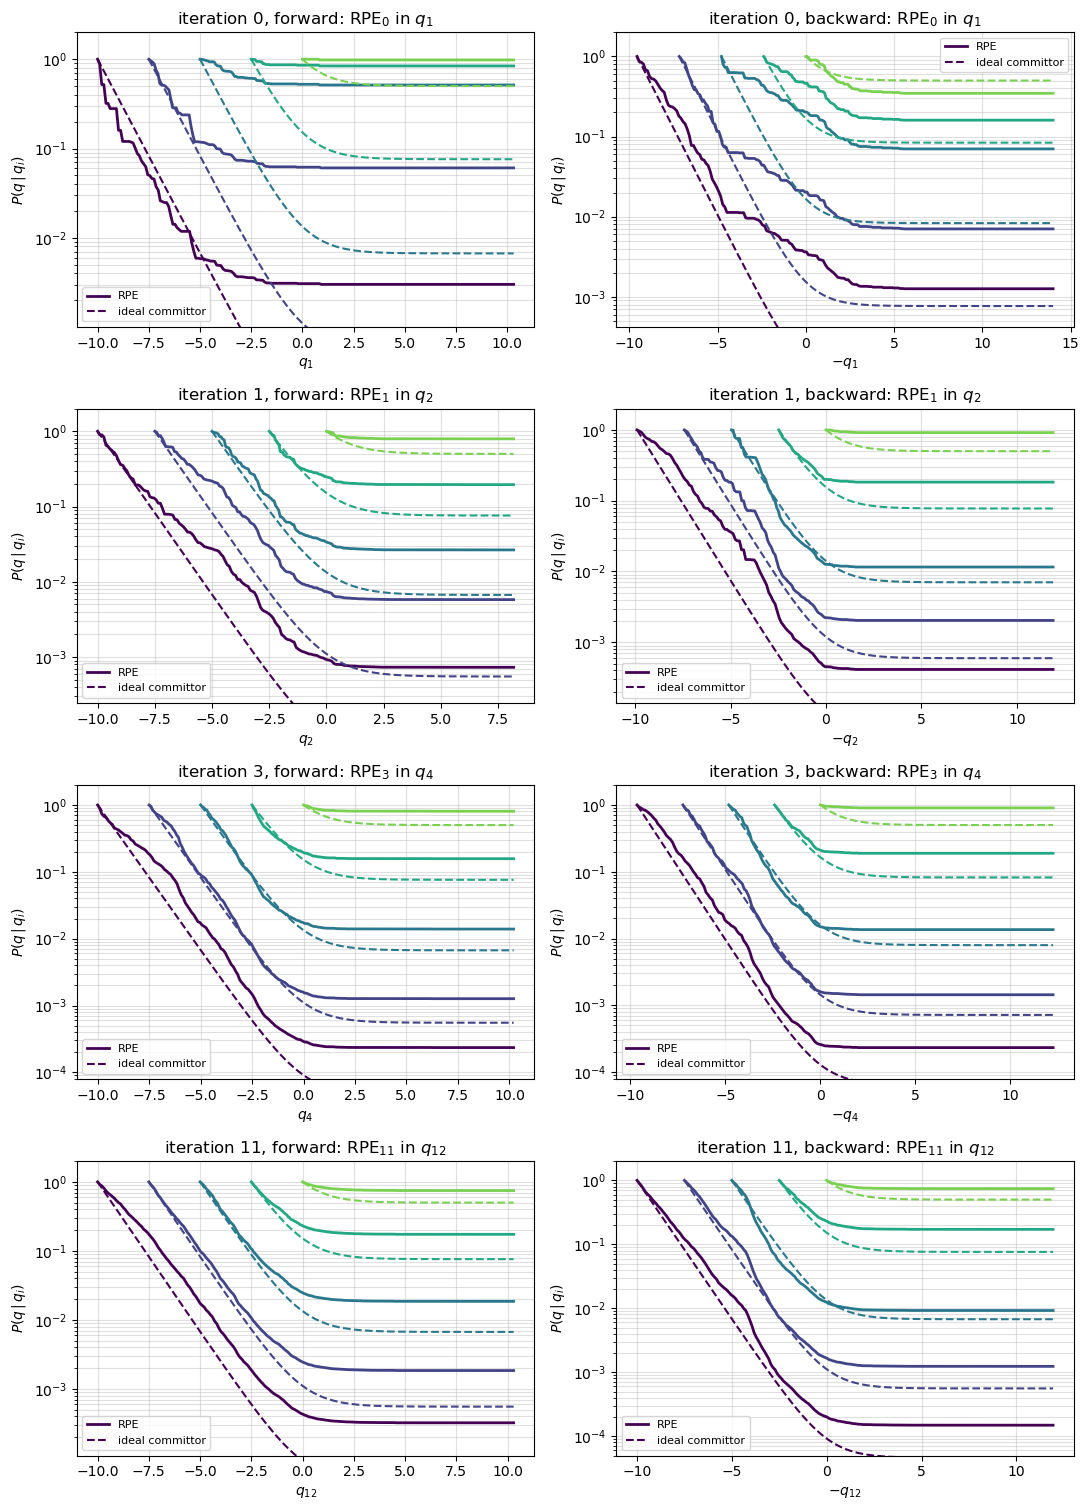

In [16]:
fig, axes = plt.subplots(len(SHOW), 2, figsize=(11, 3.8 * len(SHOW)))
for row, k in zip(axes, SHOW):
    model = wf.load_model(k + 1)
    for ax, direction in zip(row, ri.DIRECTIONS):
        dg.plot_crossing_vs_ideal(wf, k, model, direction, ax=ax, label=f"q_{{{k + 1}}}")
        ax.set_title(f"iteration {k}, {direction}: RPE$_{{{k}}}$ in $q_{{{k + 1}}}$")
fig.tight_layout()

## 4. Training balance: the chevron plot
**Left:** the weighted loss decomposed along $q$, $-\ln L(q) \propto \rho_{RPE}(q)\,I(q)$:
- the density of the RPE, $\rho^{RPE}$, is large near the states;
- the information per point, $I(q)$, is large near $q=0$.

The two compensate, which is why stable-state weights do not swamp the training.

**Right:** $p_A$, $p_B$ from the RPE shot results binned along $q$, against the logistic curves.

**What to look for:**
- $I(q)$ following the ideal (dashed) curve over the full range;
- a flat loss per point (orange);
- $p_A$, $p_B$ on the logistic lines down to small values.

A model that is too steep concentrates $I(q)$ near 0; one that is too shallow broadens it.

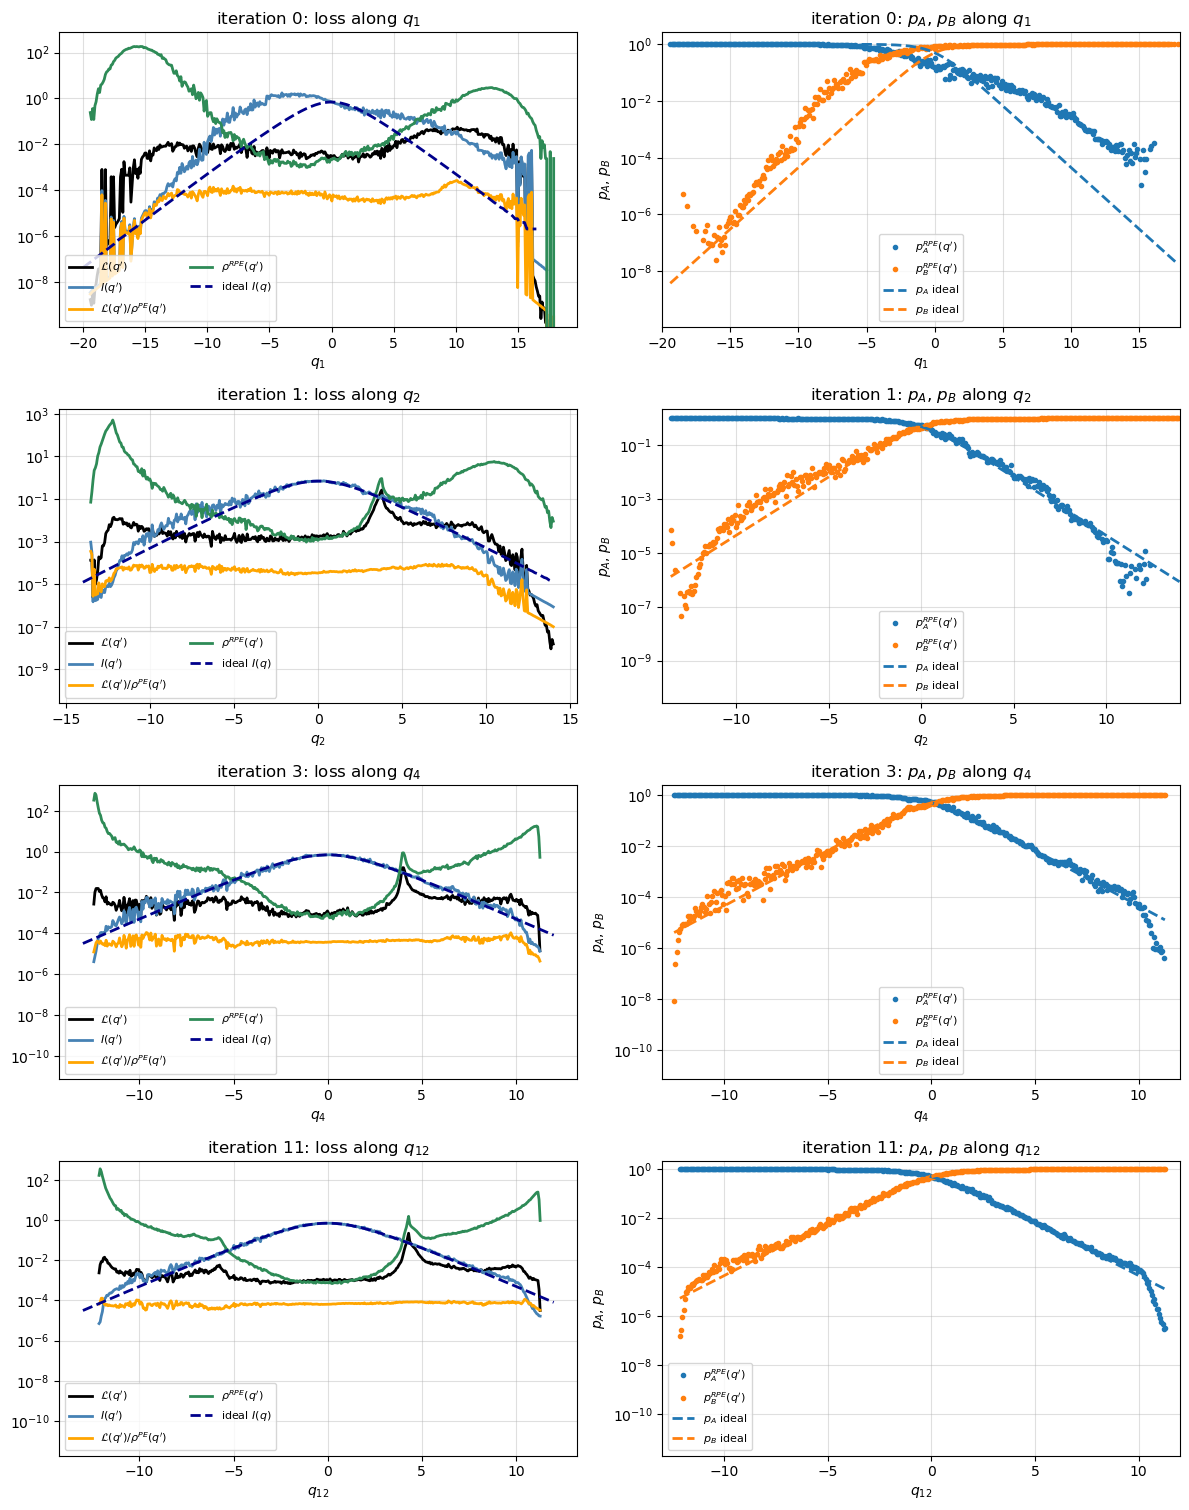

In [17]:
fig, axes = plt.subplots(len(SHOW), 2, figsize=(12, 3.8 * len(SHOW)))
for row, k in zip(axes, SHOW):
    vis, _, q_next = dg.load_iteration(wf, k)
    dg.plot_chevron(vis, q_next, axes=row, label=f"q_{{{k + 1}}}")
    row[0].set_title(f"iteration {k}: loss along $q_{{{k + 1}}}$")
    row[1].set_title(f"iteration {k}: $p_A$, $p_B$ along $q_{{{k + 1}}}$")
fig.tight_layout()

## 5. Calibration
**Left:** the logit of the committor measured from the RPE shot results, binned along the model $q$; the diagonal means calibrated.
**Right:** predicted against measured $p_B$ per bin.

**What to look for:** points on the diagonal over the whole $q$ range, not only near $q = 0$. Systematic bending at large $|q|$ is the typical failure of a model trained only on shooting points (AIMMD-TPS).

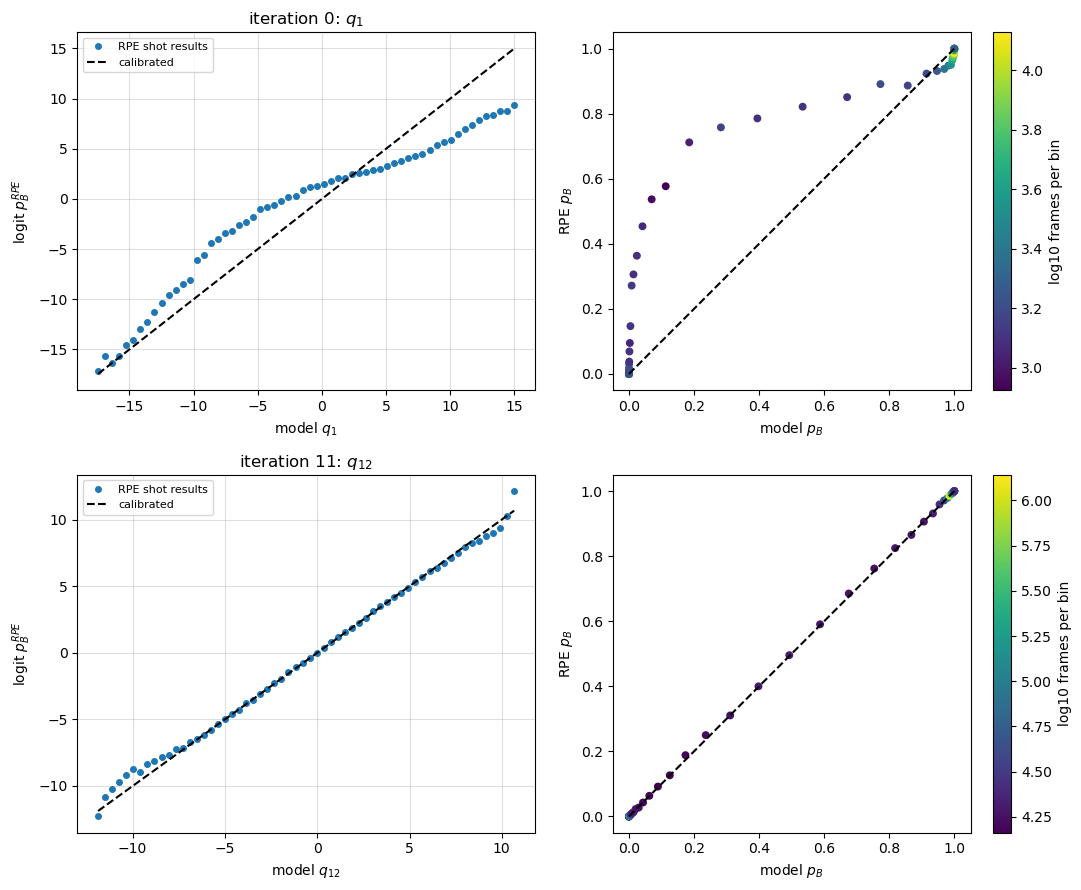

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row, k in zip(axes, (SHOW[0], SHOW[-1])):
    vis, _, q_next = dg.load_iteration(wf, k)
    dg.plot_calibration(vis, q_next, axes=row, label=f"q_{{{k + 1}}}")
    row[0].set_title(f"iteration {k}: $q_{{{k + 1}}}$")
fig.tight_layout()

## 6. Landscapes in the $(x, y)$ plane
Four views of the same reweighted path ensemble, as in the T4L mechanistic analysis:
1. the RPE free energy;
2. the committor measured directly from the RPE shot results (no model);
3. the model committor projected on the RPE frames;
4. the exact committor.

Below them are the errors against the truth on the bins the RPE samples: the free energy against $\beta V$, and the projected model $q$ against the exact $q$.

**What to look for:**
- the RPE covering the whole transition region, both channels included;
- the model projection matching the shot committor, smoothed;
- both errors shrinking from the first to the last iteration.

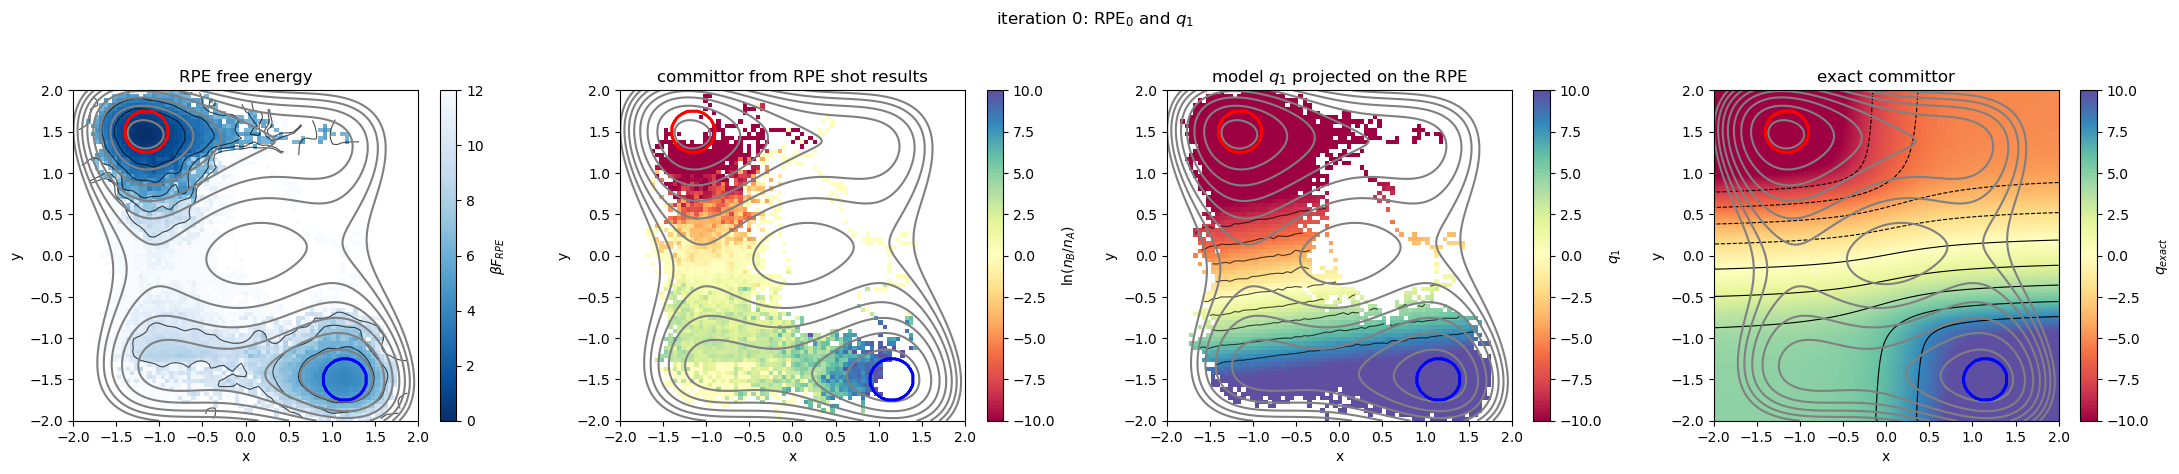

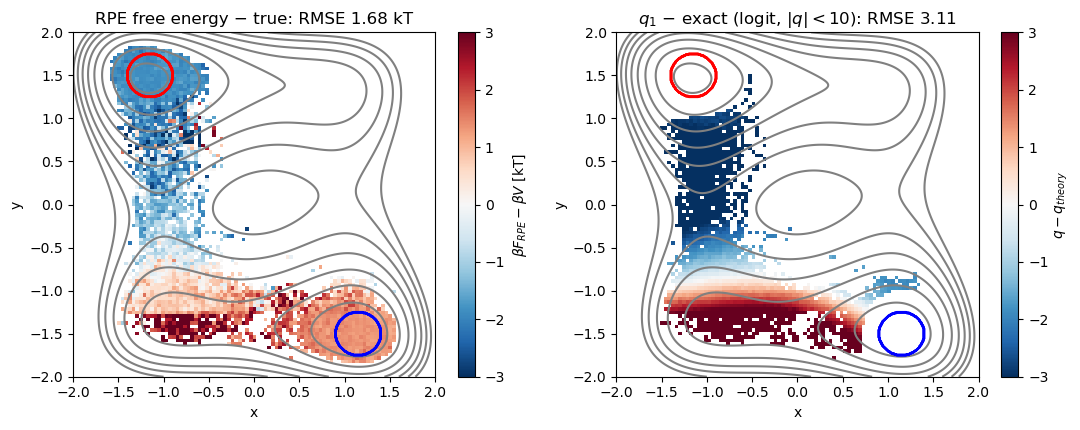

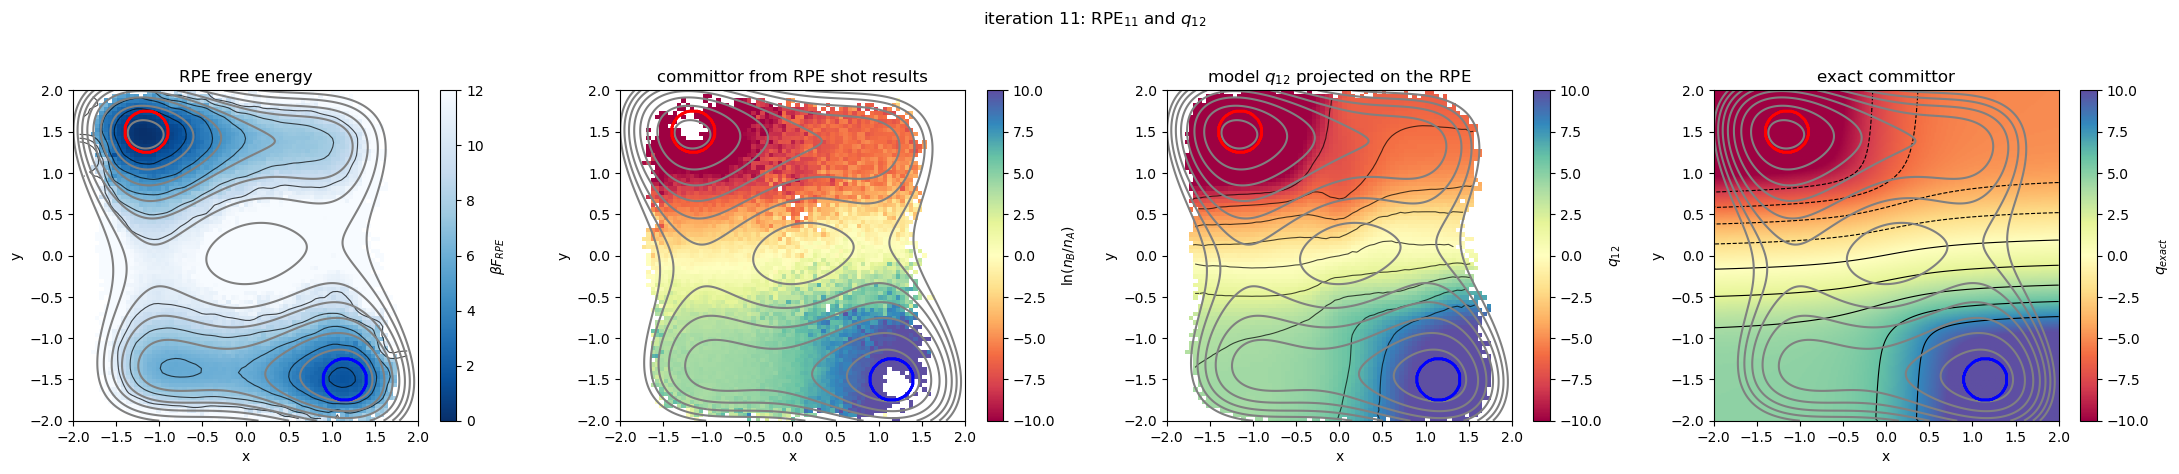

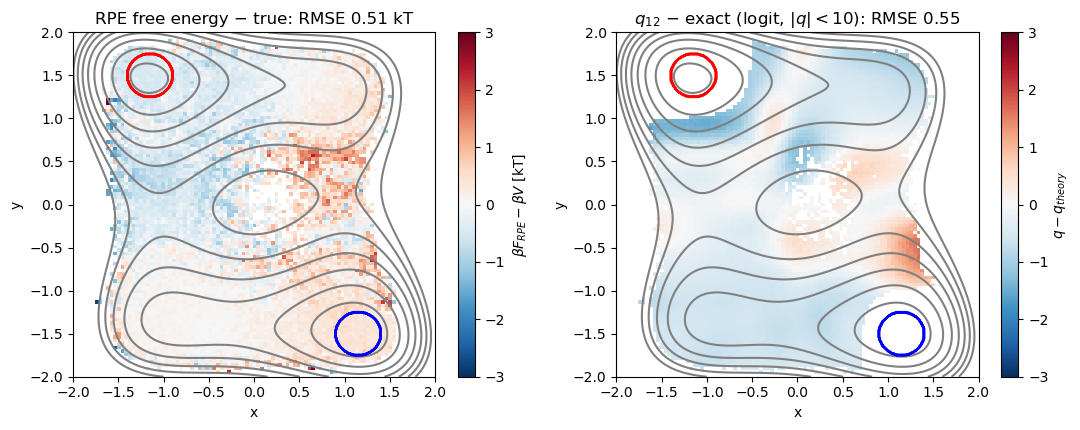

In [19]:
for k in (SHOW[0], SHOW[-1]):
    vis, _, q_next = dg.load_iteration(wf, k)
    fig, axes = plt.subplots(1, 4, figsize=(22, 4.6))
    dg.plot_landscape(vis, q_next, theory_path, axes=axes, label=f"q_{{{k + 1}}}")
    fig.suptitle(f"iteration {k}: RPE$_{{{k}}}$ and $q_{{{k + 1}}}$", y=1.02)
    fig.tight_layout()
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
    dg.plot_errors_vs_theory(vis, q_next, cfg["analysis"], axes=axes, label=f"q_{{{k + 1}}}")
    fig.tight_layout()

## 7. Mechanism along the committor (final model)
With a validated committor, descriptors can be followed along the reaction:
- **Top:** $\ln\rho(\xi|q)$, how $x$ and $y$ are distributed at each stage of the transition.
- **Bottom:** the gradient magnitude $|\nabla q|$, and the unit-gradient components $\partial q/\partial \xi_i / |\nabla q|$.

The unit gradients show which descriptor drives progress where; a positive value means increasing $\xi_i$ moves towards B.

**What to look for:**
- **Wolfe–Quapp:** $y$ dominates throughout. $x$ matters where the channel bends, and around the shallow intermediate near $(0, 0)$.
- **Higher dimensions:** with harmonic dimensions added (`n_harmonics > 0`), their gradient components should stay near zero.

/Users/rbreeba/code/aimmd-tis/src/aimmdTIS/visualization/model_analysis.py:1181: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


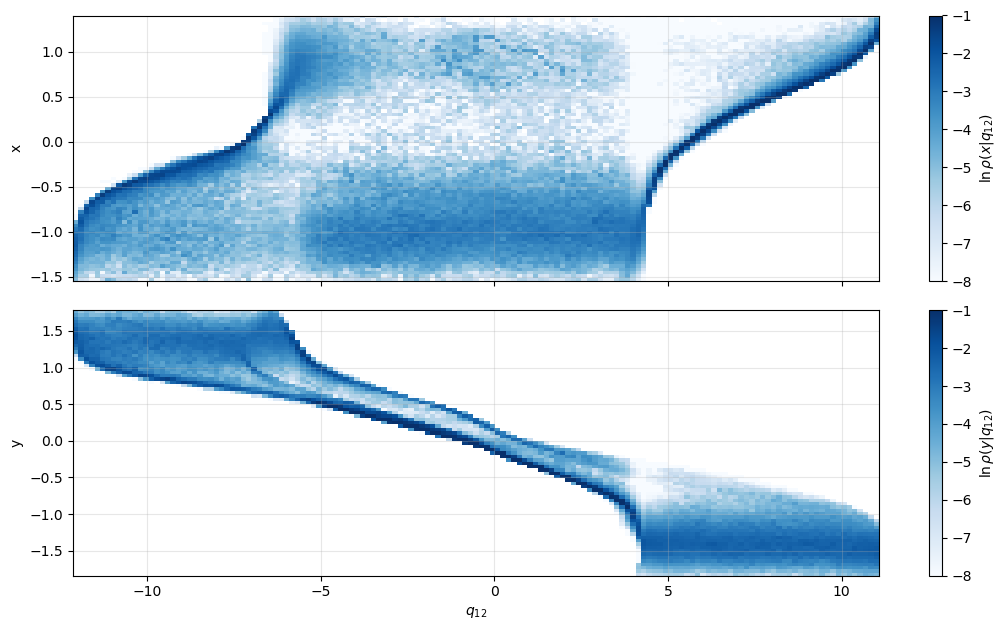

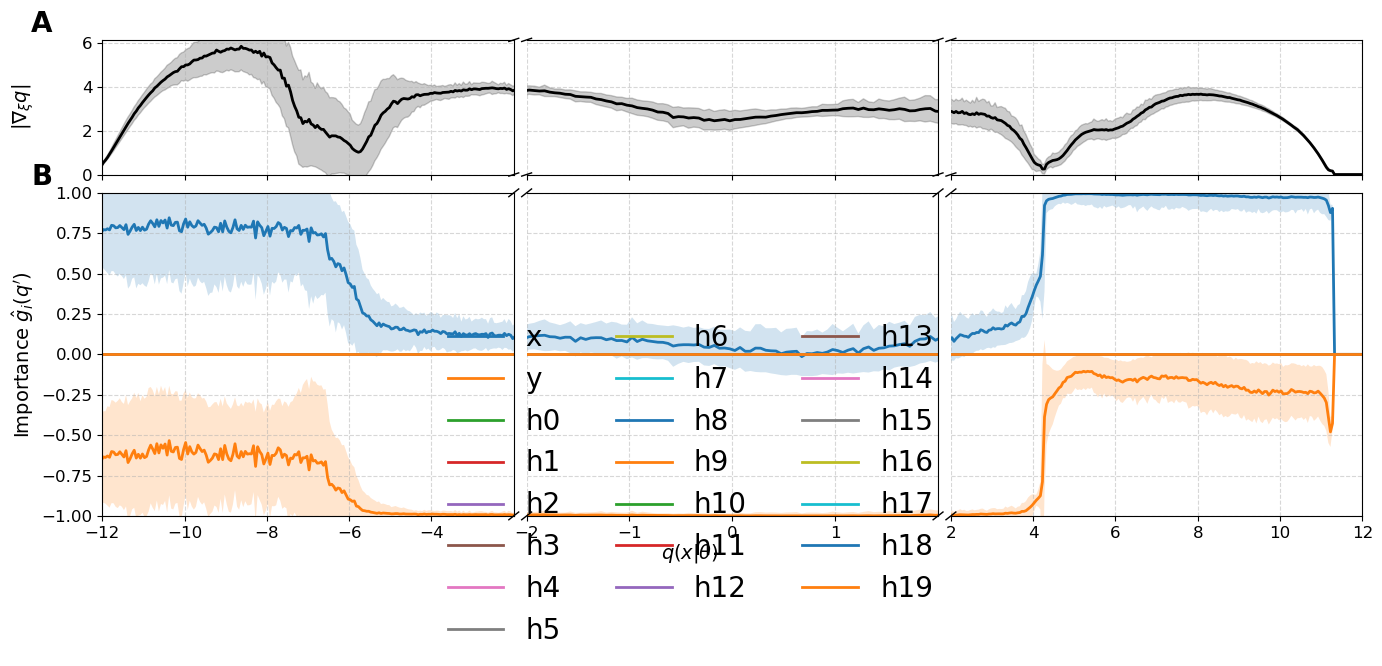

In [20]:
vis, _, q_final = dg.load_iteration(wf, LAST)
dg.plot_descriptor_density(vis, q_final, label=f"q_{{{LAST + 1}}}")
plt.tight_layout()
dg.plot_gradients(vis, q_final);

## 8. Convergence over iterations
**Panels:**
1. RPE free-energy error against the true potential;
2. committor projection error against the exact committor, for the sampling model $q_k$, the trained model $q_{k+1}$, and the shot committor (model-free; it reflects the quality of the RPE itself);
3. calibration;
4. the model change $\Delta q$ with the stopping tolerance;
5. rates with bootstrap errors, if `monitor.py` / `extras/convergence.py` have computed them.

**How to read it:**
- **Converge:** rates, crossing probabilities, calibration and coverage.
- **Plateau:** the free-energy and committor errors, at a level set by the statistics per iteration (100 TIS steps per interface here; 300 steps reaches lower errors).
- **$\Delta q$:** it decides when to stop without using the exact answer, which is what makes the loop usable on real systems.

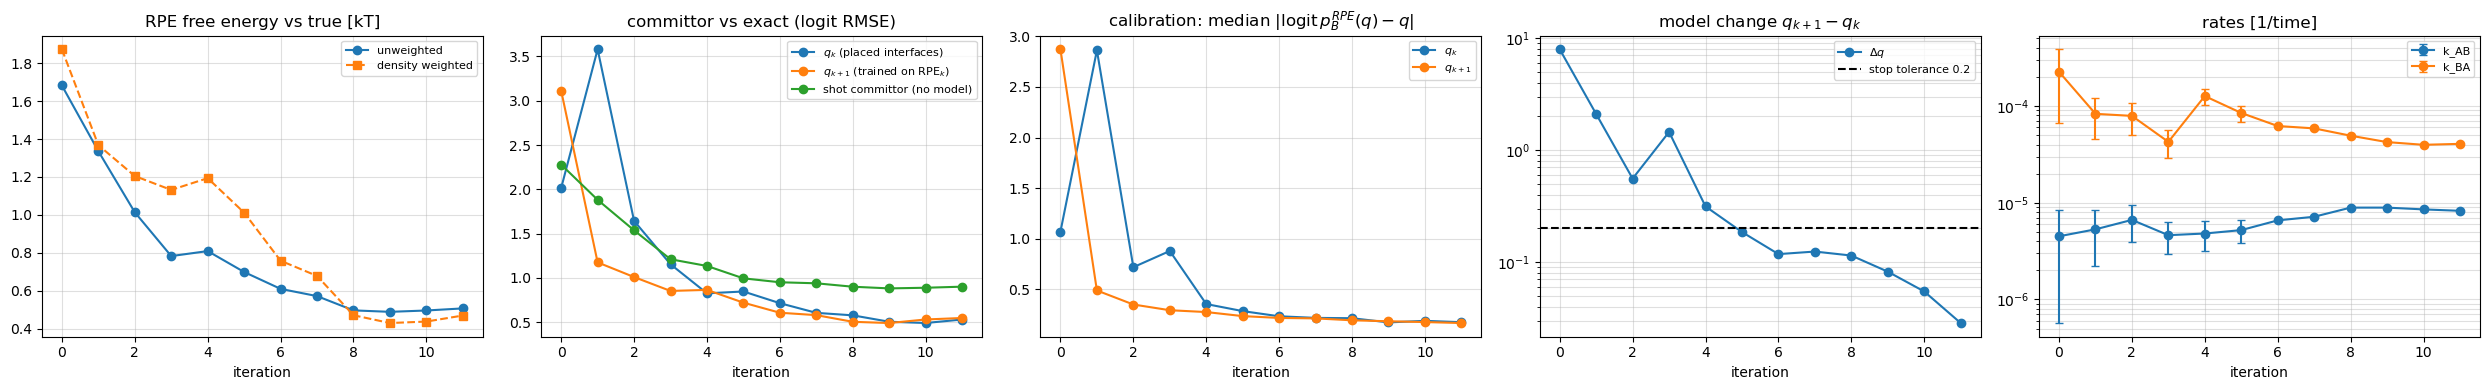

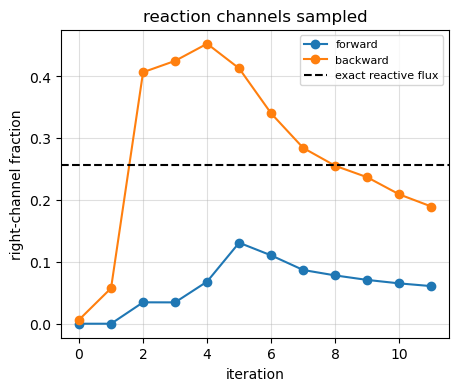

In [21]:
dg.plot_convergence(metrics, cfg)
plt.tight_layout()
dg.plot_channel_trend(metrics, wf);

## 9. Comparing runs
The same convergence metrics for a second run (`COMPARE`), for example a run without reseeding or with shorter TIS chains, plotted on top of `OUT`. Channel fractions missing from older runs are computed here.

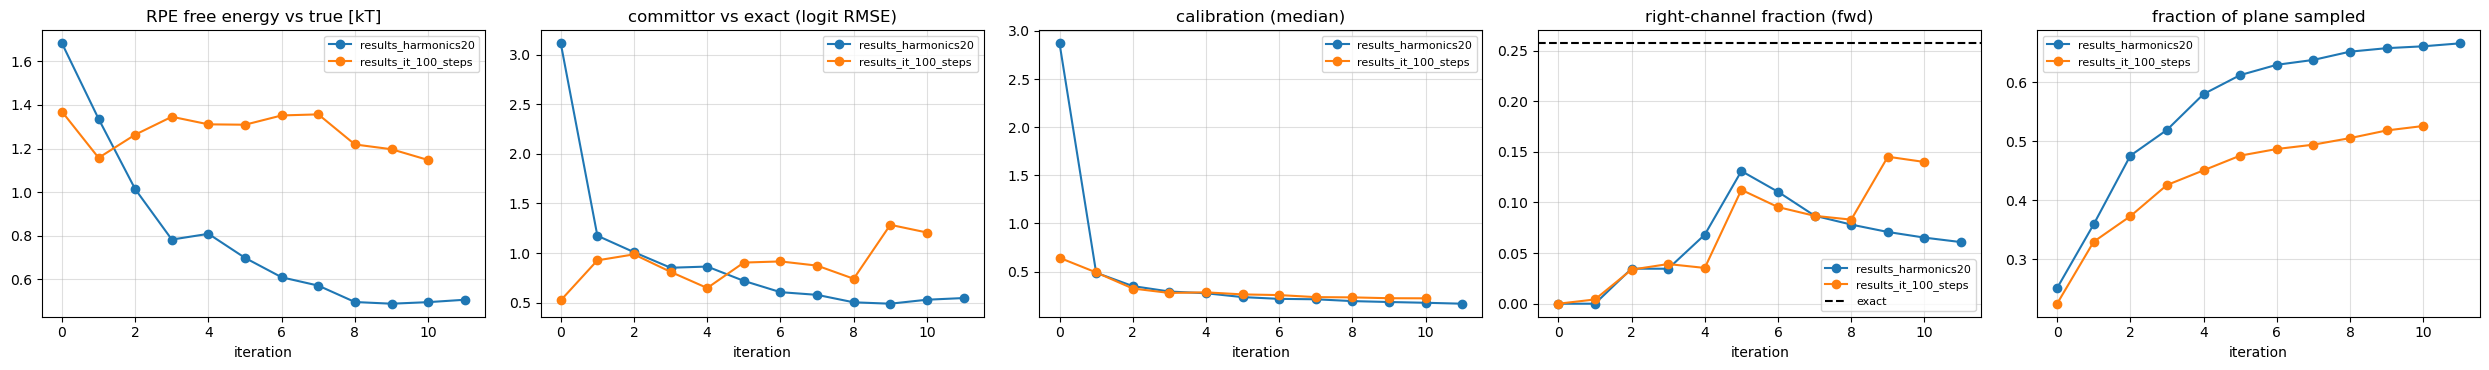

In [22]:
COMPARE = Path("results_it_100_steps")   # set to None to skip

def with_channels(out):
    with dg.quiet():
        w = ri.IterativeAimmdTIS(ri.load_run_config(out), out, n_workers=1)
    df = dg.iteration_metrics(out)
    if "channel_right_frac_fwd" not in df:
        ch = [dg.channel_fractions(w, int(k)) for k in df["iteration"]]
        for key in ch[0]:
            df[key] = [c[key] for c in ch]
    return df

if COMPARE is not None and Path(COMPARE).resolve() != OUT.resolve():
    runs = {OUT.name: with_channels(OUT), Path(COMPARE).name: with_channels(COMPARE)}
    cols = [("fe_rmse_kT", "RPE free energy vs true [kT]"), ("q_next_proj_rmse_logit", "committor vs exact (logit RMSE)"),
            ("q_next_calib_median", "calibration (median)"), ("channel_right_frac_fwd", "right-channel fraction (fwd)"),
            ("fe_coverage", "fraction of plane sampled")]
    fig, axes = plt.subplots(1, len(cols), figsize=(5 * len(cols), 3.8))
    for ax, (col, title) in zip(axes, cols):
        for name, df in runs.items():
            ax.plot(df["iteration"], df[col], "o-", label=name)
        if col.startswith("channel"):
            ax.axhline(dg.theory_channel_fraction(wf), color="k", ls="--", label="exact")
        ax.set_title(title); ax.set_xlabel("iteration"); ax.grid(alpha=0.4); ax.legend(fontsize=8)
    fig.tight_layout()